# Analysis 1: Data Quality Audit, Age-Related Resale-Price Curve & Age-25 Anomaly Investigation
**Jira User Story:** `CDS-76` — Advanced Analysis (Acceptance Criterion 1)  
**Dataset:** `../data/final_destination.csv` (15,229 used-car listings, 15 columns)

> **Analytical Framing:** This dataset contains **cross-sectional used-car listings** (not longitudinal tracking of individual cars and not confirmed completed transactions). All age patterns below describe **estimated age-related listing-price differences**, not true longitudinal depreciation.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

SCRIPTS_DIR = Path("scripts").resolve()
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from common import load_dataset, inspect_data_quality, OUTPUT_FIG_DIR
from depreciation_analysis import (
    compute_age_summary,
    investigate_age_25_anomaly,
    run_depreciation_analysis,
)

df = load_dataset()
dq = inspect_data_quality(df)
print(f"Dataset shape: {dq['rows']:,} rows x {dq['columns']} columns")
print(f"Total missing values: {dq['total_missing']} | Exact duplicates: {dq['duplicate_rows']}")
print("Domain checks:", dq["domain_checks"])
print("Low-sample ages (n < 30):", dq["low_sample_ages_lt_30"])
print("Body-type counts:", dq["body_type_counts"])

Dataset shape: 15,229 rows x 15 columns
Total missing values: 0 | Exact duplicates: 0
Domain checks: {'extreme_km_per_year_gt_100k': 0, 'zero_vehicle_age_rows': 4, 'non_positive_selling_price': 0, 'non_positive_km_driven': 0, 'non_positive_engine': 0, 'non_positive_max_power': 0, 'unknown_real_body_type': 5317, 'unknown_real_typical_owner_type': 304}
Low-sample ages (n < 30): {0: 4, 16: 25, 17: 17, 18: 11, 19: 5, 21: 3, 22: 1, 25: 1, 29: 1}
Body-type counts: {'Unknown': 5317, 'Hatchback': 3601, 'Sedan': 2839, 'SUV': 2819, 'MUV': 558, 'Crossover, SUV': 54, 'MPV': 24, 'Sports, Convertible': 6, 'Pick-up': 6, 'Coupe': 4, 'Sports': 1}


### Initial Data-Quality Summary
- **Dimensions & Completeness:** `final_destination.csv` contains **15,229 rows and 15 columns** with **0 missing values** and **0 exact duplicate rows**.
- **Domain & Range Verification:** All `selling_price` (`₹40,000` to `₹39,500,000`), `km_driven` (`100` to `830,000`), `engine` (`793` to `6,592` cc), and `max_power` (`38.4` to `626.0` bhp) values are strictly positive, with 0 extreme `km_per_year > 100,000` records.
- **Important Data Caveats:**
  - `real_body_type` contains **5,317 `"Unknown"`** listings (34.9%) and several sparse/single-transmission body types (`MPV` n=24, `Pick-up` n=6, `Sports, Convertible` n=6, `Coupe` n=4, `Sports` n=1).
  - `real_typical_owner_type` contains **304 `"Unknown"`** records (2.0%).
  - `real_new_ex_showroom_price` is pre-scaled (`0.125` to `0.99`) and ~34.9% of values were median-imputed (`0.5195`) during prior cleaning.
  - **9 age groups have `n < 30`:** ages `0` (`4`), `16` (`25`), `17` (`17`), `18` (`11`), `19` (`5`), `21` (`3`), `22` (`1`), `25` (`1`), `29` (`1`) — totaling 68 listings (`0.45%`).

In [2]:
age_summary = compute_age_summary(df)
display_cols = [
    "vehicle_age", "count", "median_price", "mean_price",
    "p25_price", "p75_price", "yoy_pct_change", "low_sample_flag"
]
display(age_summary[display_cols].style.format({
    "median_price": "₹{:,.0f}",
    "mean_price": "₹{:,.0f}",
    "p25_price": "₹{:,.0f}",
    "p75_price": "₹{:,.0f}",
    "yoy_pct_change": "{:+.2f}%"
}))

,vehicle_age,count,median_price,mean_price,p25_price,p75_price,yoy_pct_change,low_sample_flag
0,0,4,"₹525,000","₹1,575,000","₹475,000","₹1,625,000",+nan%,True
1,1,220,"₹750,000","₹1,099,236","₹550,000","₹1,056,250",+42.86%,False
2,2,1134,"₹818,000","₹1,143,010","₹586,250","₹1,098,000",+9.07%,False
3,3,1896,"₹748,000","₹977,327","₹550,000","₹950,000",-8.56%,False
4,4,2216,"₹695,500","₹949,496","₹518,000","₹911,250",-7.02%,False
5,5,2089,"₹600,000","₹820,221","₹450,000","₹789,000",-13.73%,False
6,6,1901,"₹550,000","₹728,021","₹450,000","₹700,000",-8.33%,False
7,7,1427,"₹500,000","₹700,072","₹395,000","₹650,000",-9.09%,False
8,8,1271,"₹450,000","₹627,511","₹350,000","₹600,000",-10.00%,False
9,9,1014,"₹400,000","₹592,262","₹300,000","₹600,000",-11.11%,False


### Age-Related Listing-Price Curve & Milestone Observations
- **Reliable Age Range (`n >= 30`):** Ages **1 through 15** cover **15,161 listings (99.55%)**.
- **Peak Reliable Median:** Age **2** (`₹8.18 Lakh`, n=1,134); Age 1 (`₹7.50 Lakh`, n=220) is slightly lower due to entry-level model composition, while Age 0 (`₹5.25 Lakh`, n=4) is too small to interpret.
- **Mid-Life Plateau & Inflection Points:** After a `-13.7%` drop at Age 5 (`₹6.96L -> ₹6.00L`), median listing prices decline steadily by `₹0.50L/year` (`-8.3%` to `-11.1%`) across **Ages 6–9** before accelerating past **Age 10** (`-16.1%` at Age 10, `-19.2%` at Age 13, and `-25.0%` — the largest reliable YoY drop — at Age 15).

In [3]:
anomaly = investigate_age_25_anomaly(df)
print("Age 25 count:", anomaly["age_25_count"])
print("\nAge 25 full record:")
display(pd.DataFrame(anomaly["age_25_records"]))
print("\nNeighboring older ages comparison:")
display(pd.DataFrame(anomaly["neighbor_comparison"]))
print(f"\nOther model '3' stats (n={anomaly['model_3_total_count']-1}): max age={anomaly['model_3_other_max_age']}, median age={anomaly['model_3_other_median_age']}, median price=₹{anomaly['model_3_other_median_price']:,.0f}")
print("Recommendation:", anomaly["recommendation"])

Age 25 count: 1

Age 25 full record:


,model,vehicle_age,km_driven,seller_type,transmission_type,mileage,engine,max_power,selling_price,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,model_grouped
0,3,25,50000,Individual,Automatic,11.9,1995,154.0,1000000,First,1.26,Series 320d,0.5195,SUV,3



Neighboring older ages comparison:


,vehicle_age,count,median_price,mean_price,models
0,21,3,85000.0,73333.333333,[Wagon R]
1,22,1,70000.0,70000.000000,[City]
2,24,0,NaN,NaN,[]
3,25,1,1000000.0,1000000.000000,[3]
4,26,0,NaN,NaN,[]
5,29,1,60000.0,60000.000000,[Alto]



Other model '3' stats (n=151): max age=13, median age=7.0, median price=₹1,650,000
Recommendation: RETAIN in master dataset with explicit data-quality flag; EXCLUDE from primary age-curve milestones and reliable-age regression models (n = 1 < 30 threshold, and record exhibits both a probable clerical age error and a body-type enrichment mismatch).


### Special Investigation: Age-25 Anomaly
- **Root Cause:** The spike to `₹1,000,000` (`₹10.00 Lakh`) at `vehicle_age = 25` is driven by **a single observation (`n = 1`, row 15151)**: `model = "3"` (`Series 320d`, Automatic, `1995 cc`, `154 bhp`, `50,000 km`, `Individual`).
- **Evidence of Clerical / Enrichment Error:** All other 151 `model == "3"` listings have a **maximum age of 13 years** (median age `7.0`), and row 15151 is also mislabeled `real_body_type = "SUV"`. Neighboring older ages (`21` n=3 `₹0.85L`, `22` n=1 `₹0.70L`, `29` n=1 `₹0.60L`, with `24` and `26` absent) confirm mass-market older cars list below `₹1.00L`.
- **Decision:** Retain in the master file with an explicit anomaly flag, and **exclude all `n < 30` age groups** from primary milestone reporting and reliable-age regression fits.

,subset,model,n_obs,r2_price_scale,log_r2,rmse_inr,mae_inr,aic
0,"Reliable Ages (n >= 30, ages 1-15)",Linear OLS (Price ~ Age),15161,0.056479,NaN,869624.107716,427154.912286,457707.157179
1,"Reliable Ages (n >= 30, ages 1-15)",Polynomial Deg 2 (Price ~ Age + Age^2),15161,0.056788,NaN,869481.443186,426637.490110,457704.182353
2,"Reliable Ages (n >= 30, ages 1-15)",Polynomial Deg 3 (Price ~ Age + Age^2 + Age^3),15161,0.056858,NaN,869449.291923,426678.325939,457705.061100
3,"Reliable Ages (n >= 30, ages 1-15)",Log-Linear OLS (log(Price) ~ Age),15161,0.055975,0.219404,869856.177575,427540.546548,27507.622908
4,"Reliable Ages (n >= 30, ages 1-15)",Piecewise Log-Linear (knots at Age 5 & 10),15161,0.056790,0.226800,869480.473359,425804.764290,27367.282828
5,"All Ages (ages 0-29, sensitivity)",Linear OLS (Price ~ Age),15229,0.058472,NaN,868335.255831,426465.133122,459719.530992
6,"All Ages (ages 0-29, sensitivity)",Polynomial Deg 2 (Price ~ Age + Age^2),15229,0.058856,NaN,868158.112960,425530.418838,459710.802394
7,"All Ages (ages 0-29, sensitivity)",Polynomial Deg 3 (Price ~ Age + Age^2 + Age^3),15229,0.058849,NaN,868161.156697,425517.474276,459712.761818
8,"All Ages (ages 0-29, sensitivity)",Log-Linear OLS (log(Price) ~ Age),15229,0.057869,0.236187,868613.299162,426981.989924,27681.183275
9,"All Ages (ages 0-29, sensitivity)",Piecewise Log-Linear (knots at Age 5 & 10),15229,0.058835,0.244011,868167.697841,425147.109652,27528.385619



Multivariate controlled age effect (Ages 1-15, n=15,161):
{'n_obs': 15161, 'r2': 0.9228571640035002, 'adj_r2': 0.922365547417224, 'vehicle_age_coef': -0.11205691485932437, 'vehicle_age_se': 0.0009391605787055774, 'vehicle_age_pval': 0.0, 'vehicle_age_pct_effect_per_year': -10.600662545477624, 'vehicle_age_ci95': [-0.11389763576928709, -0.11021619394936165]}
--- depreciation_curve.png ---


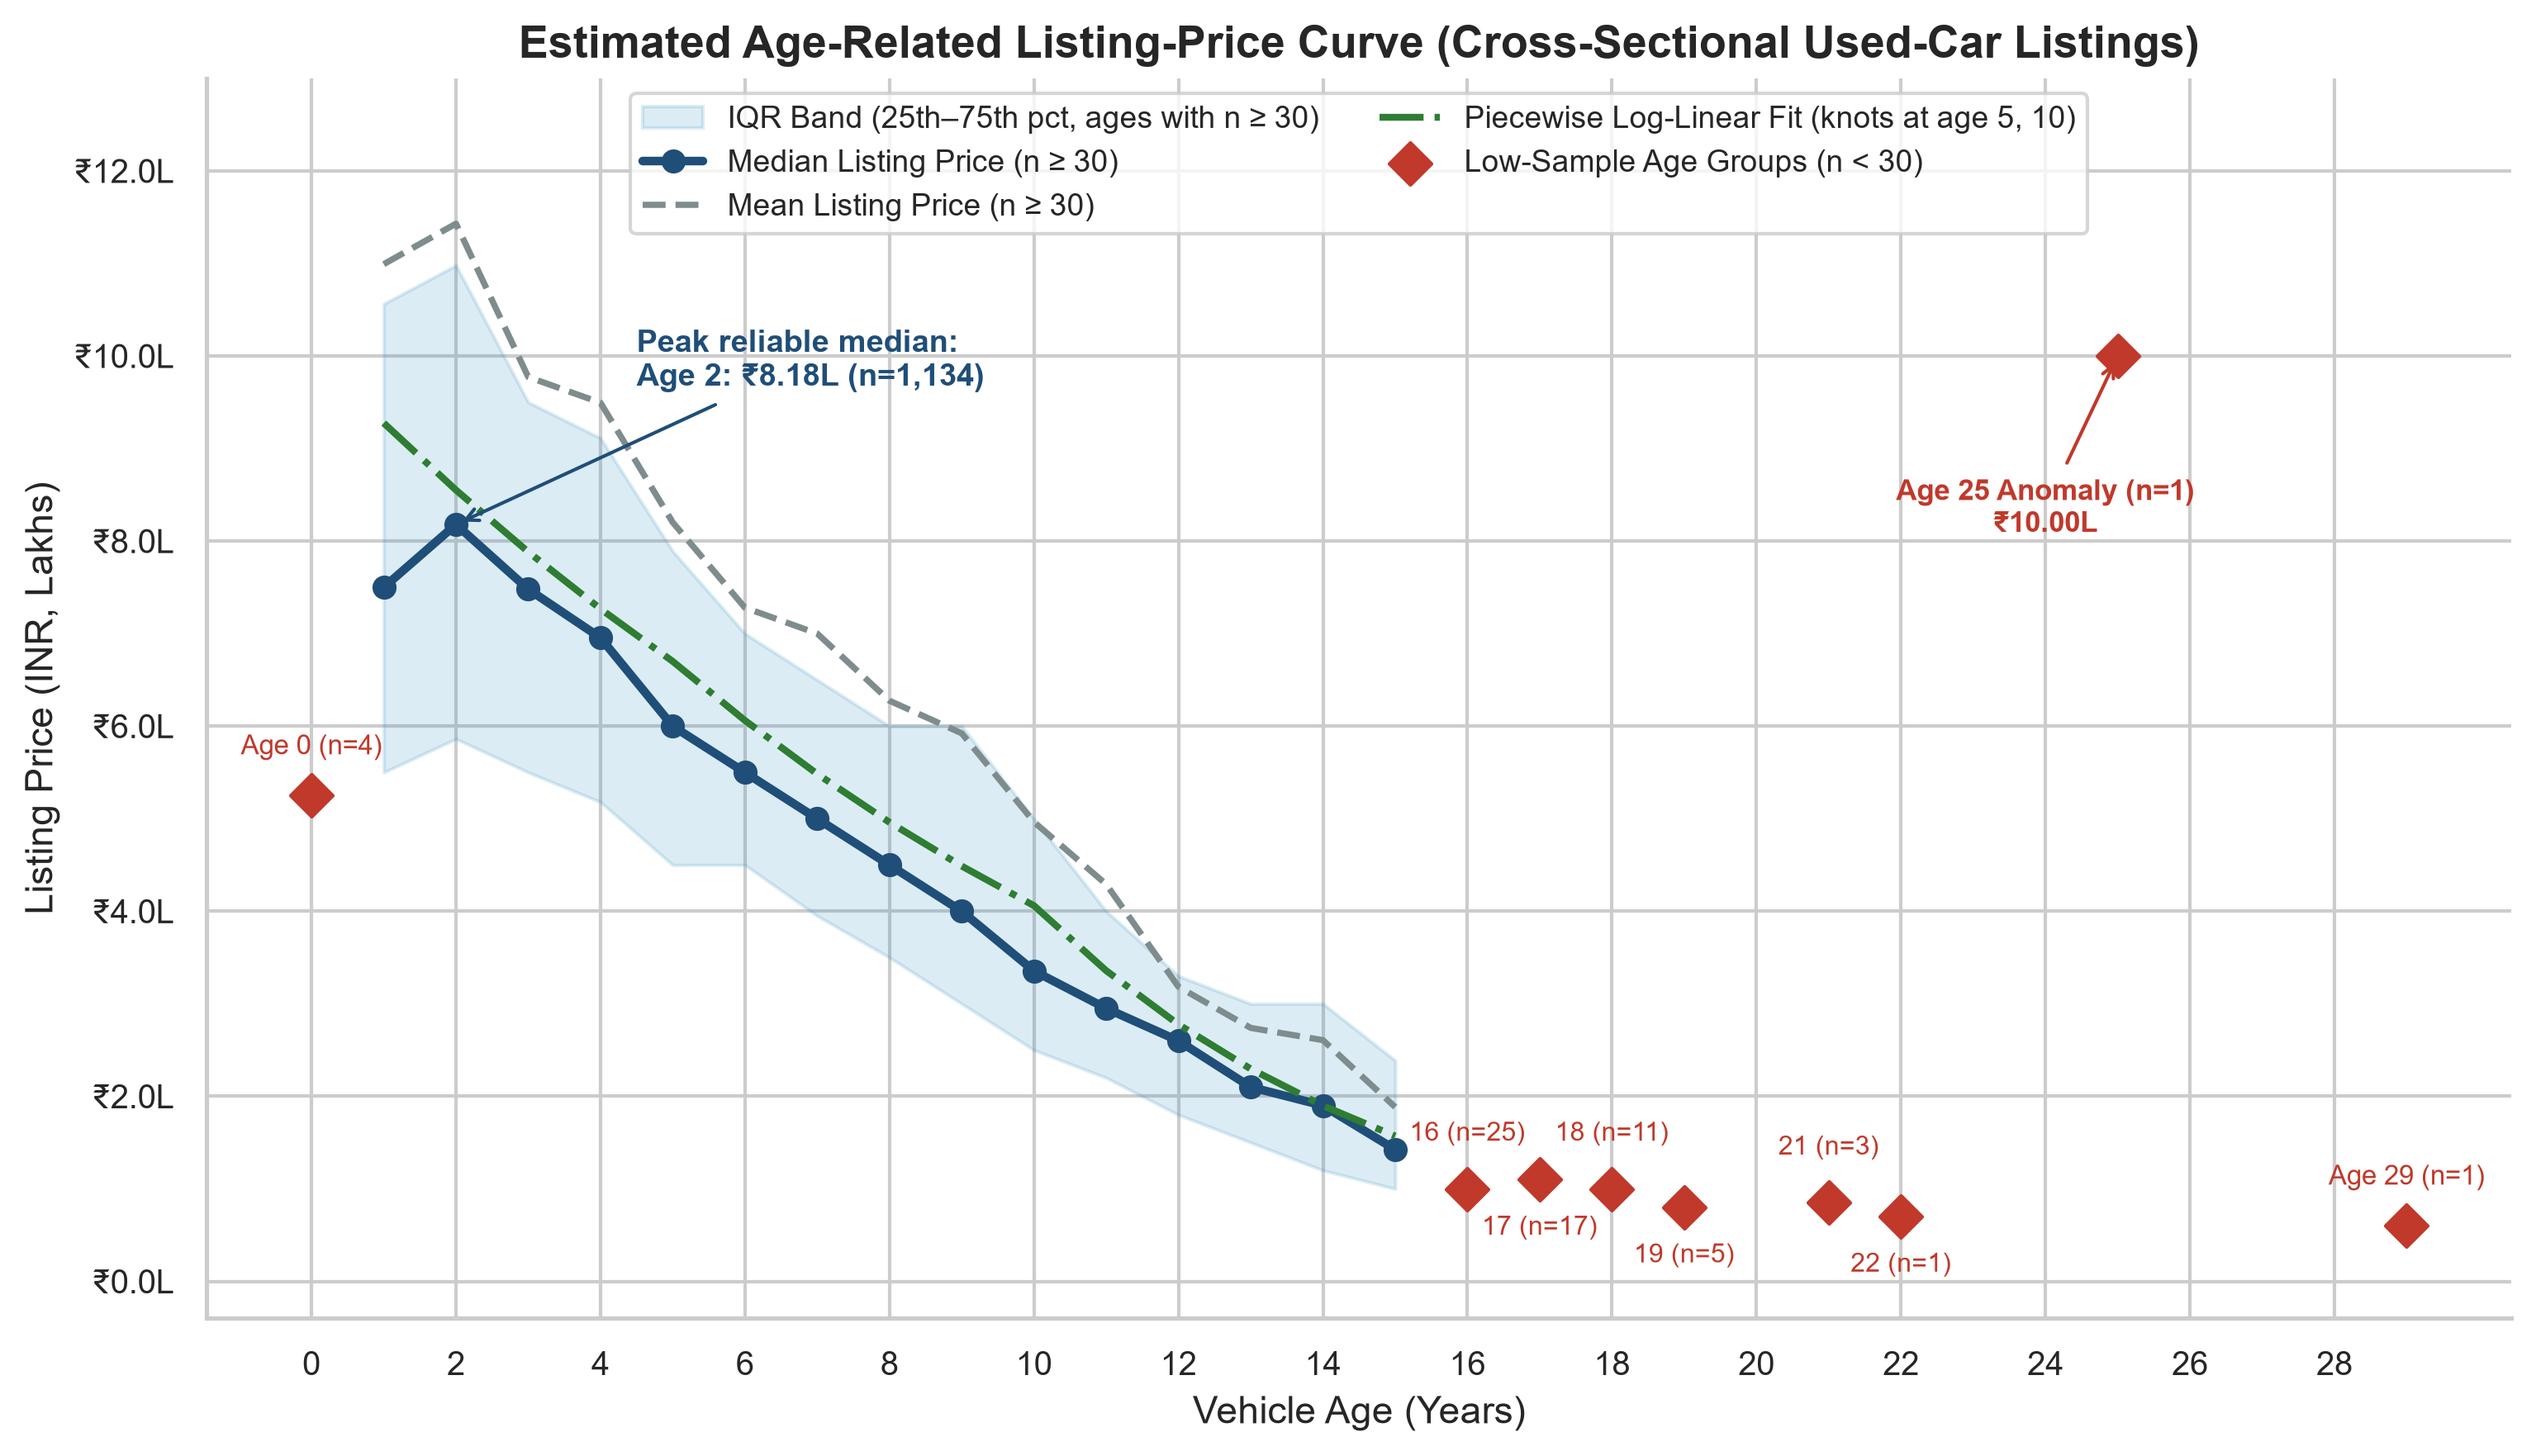

--- vehicle_age_sample_size.png ---


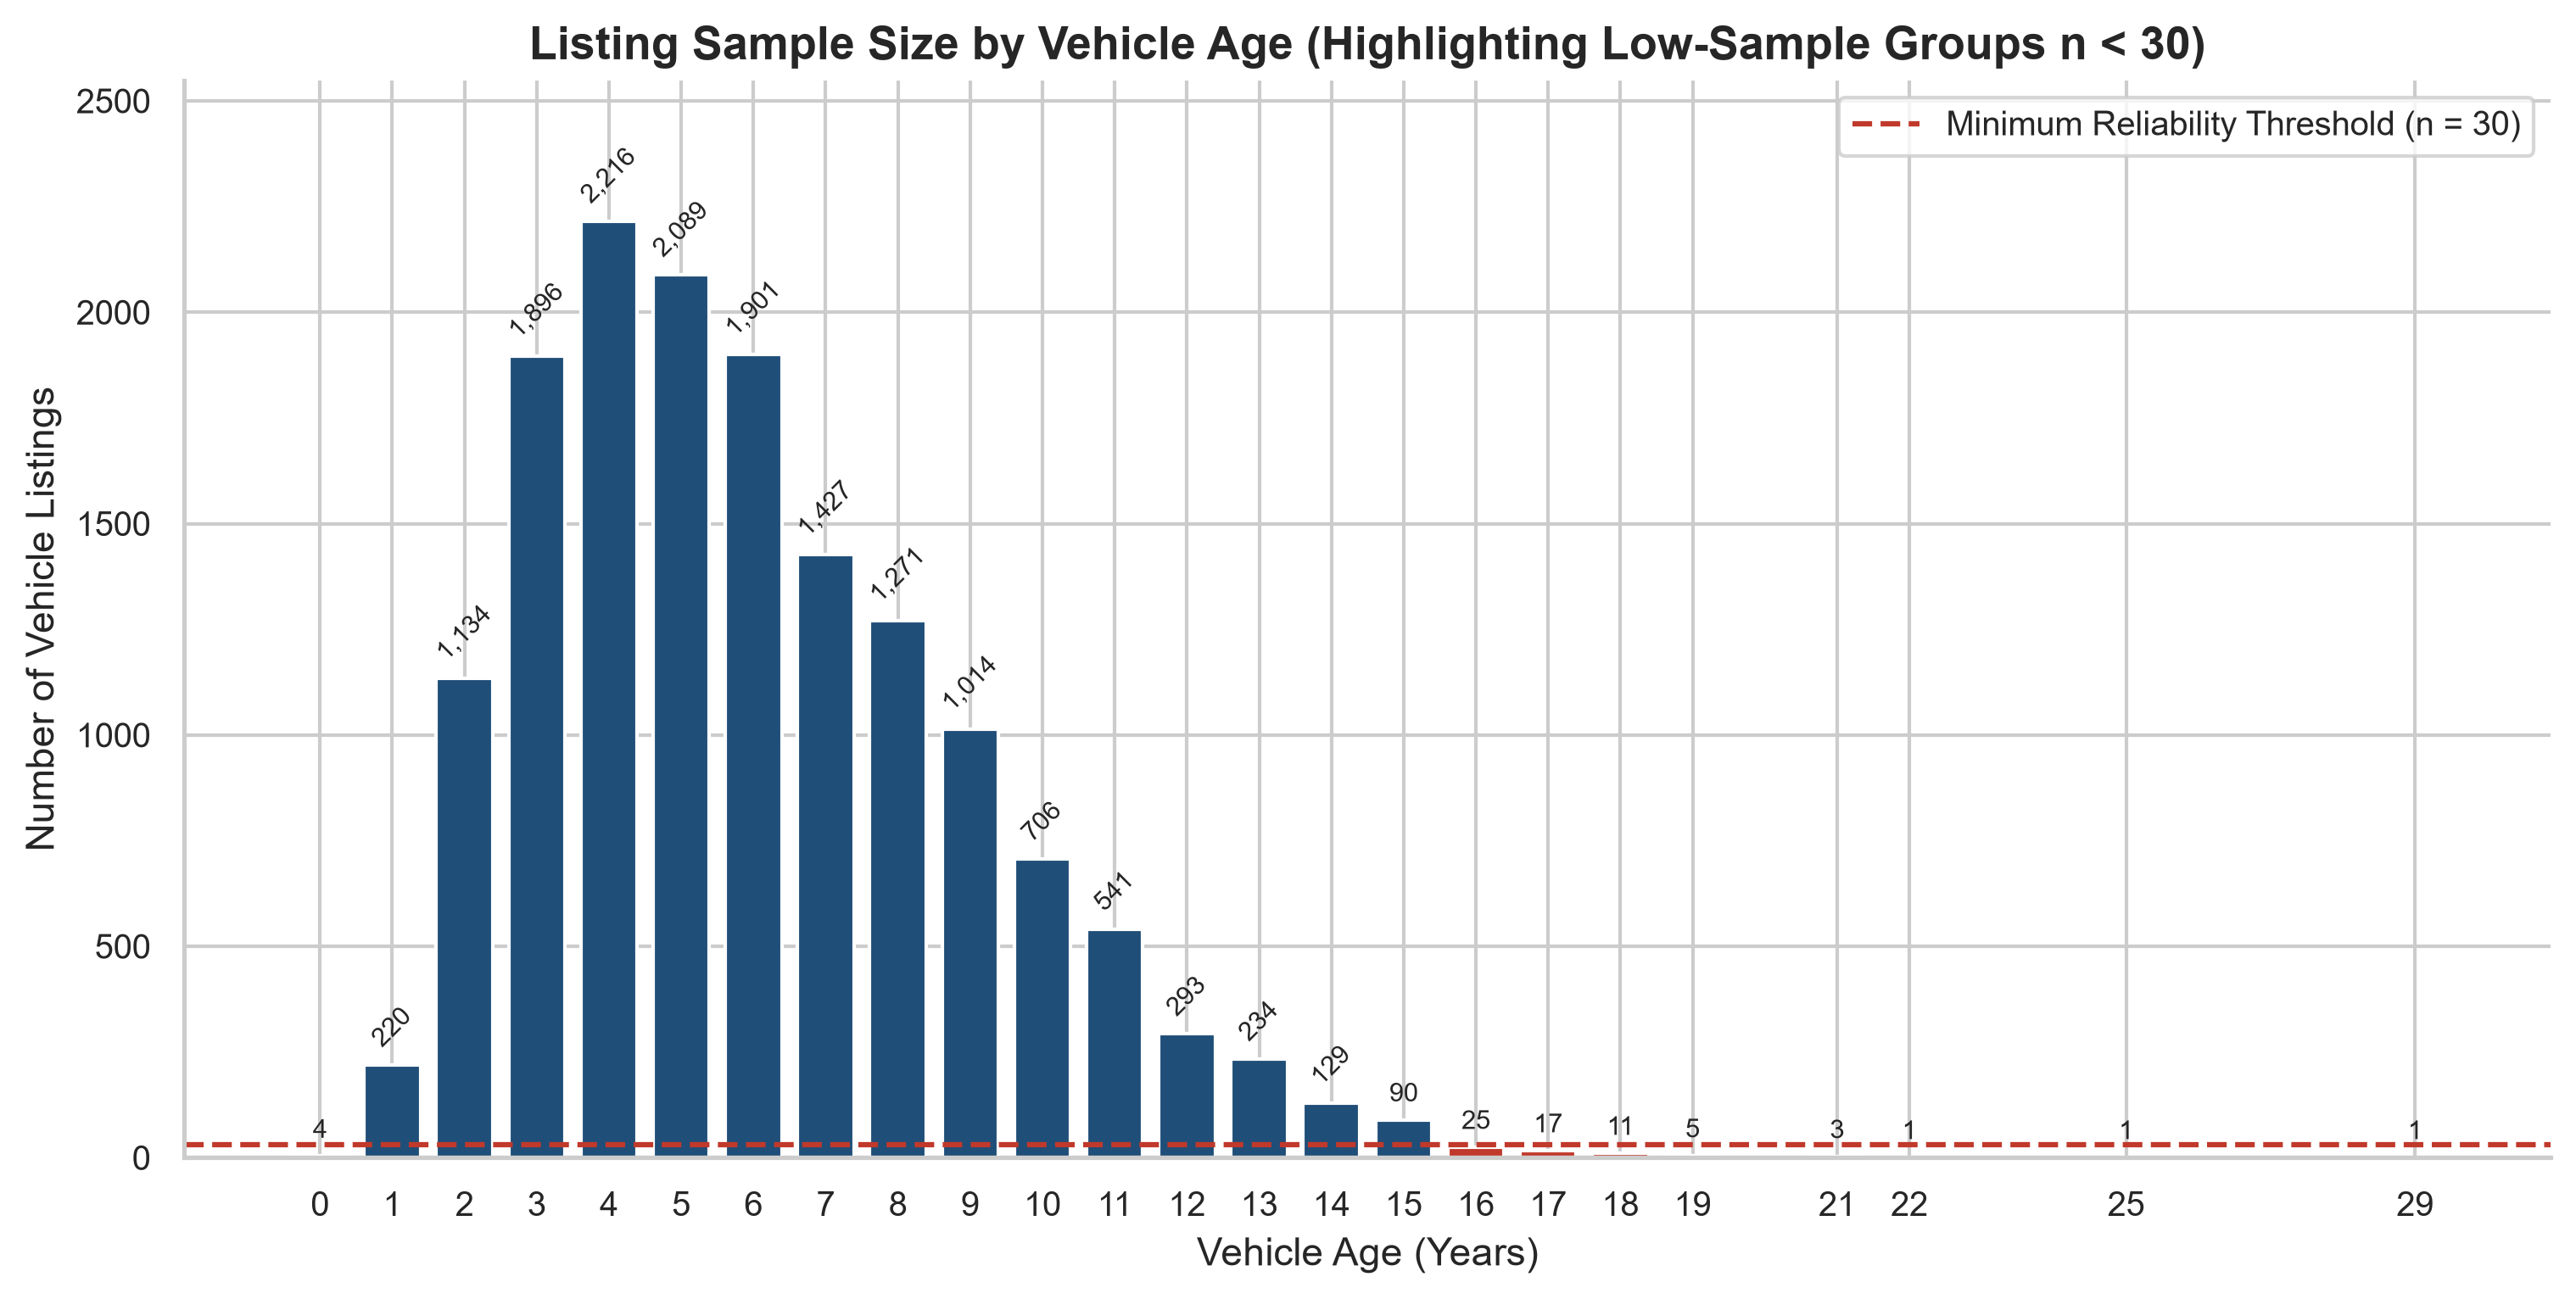

--- annual_price_change.png ---


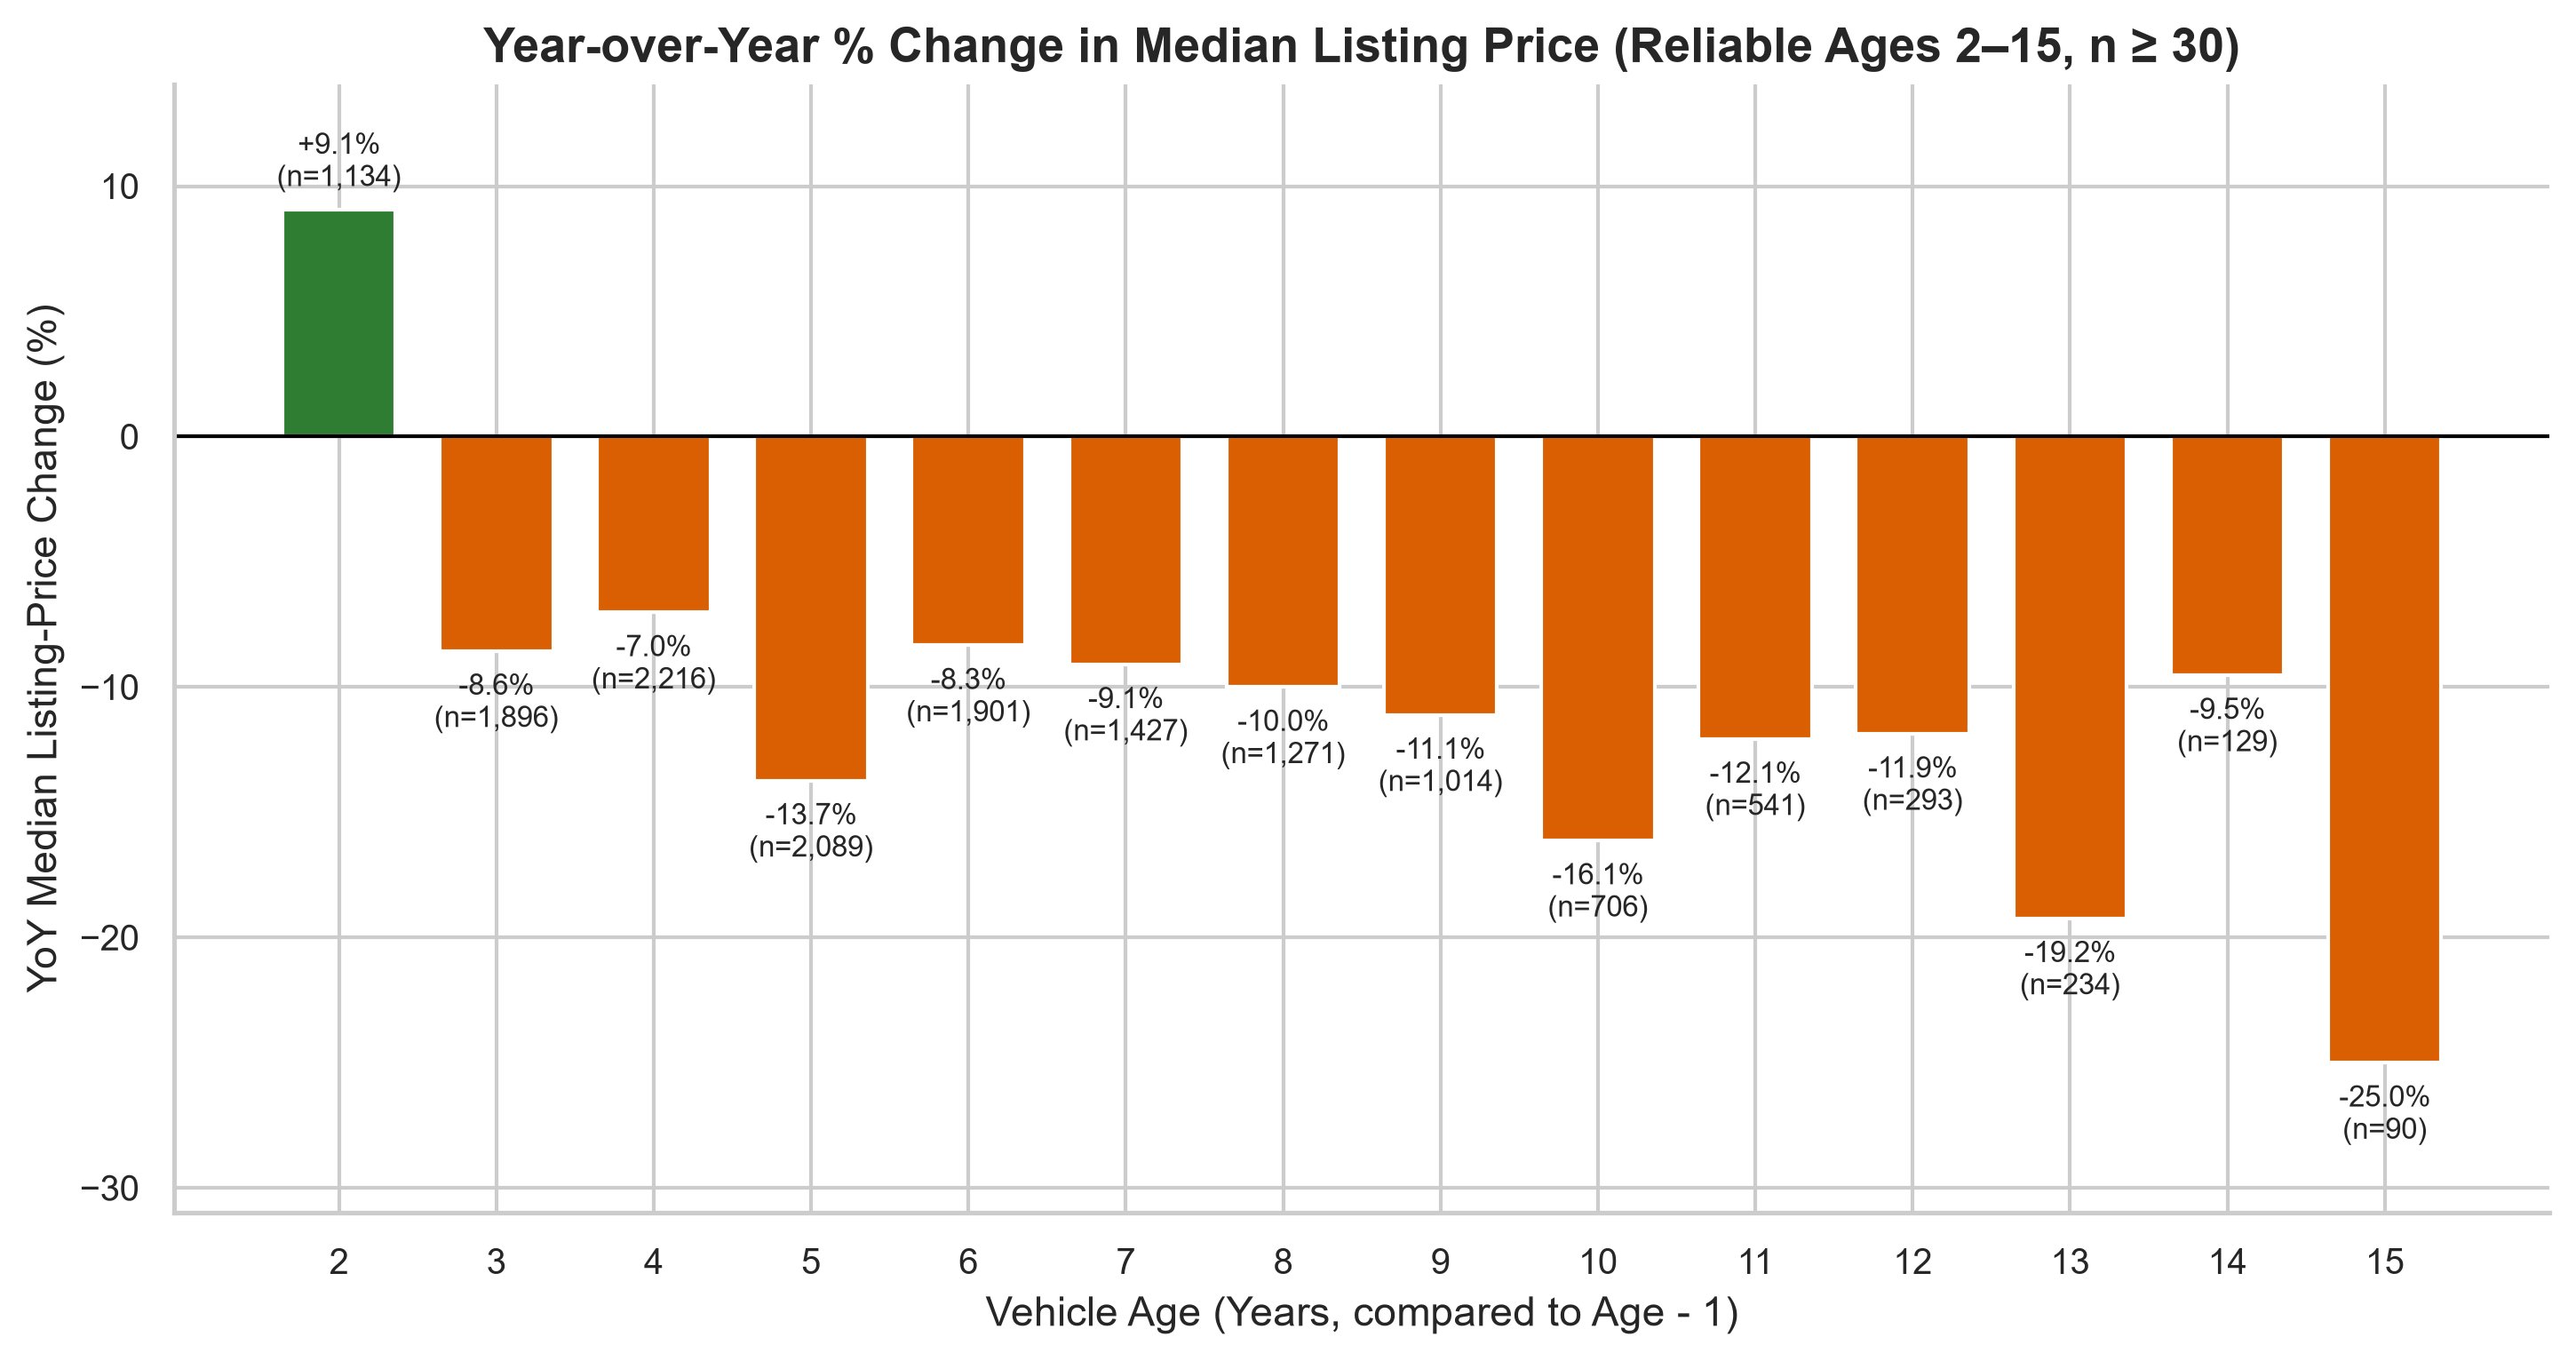

--- age_25_anomaly.png ---


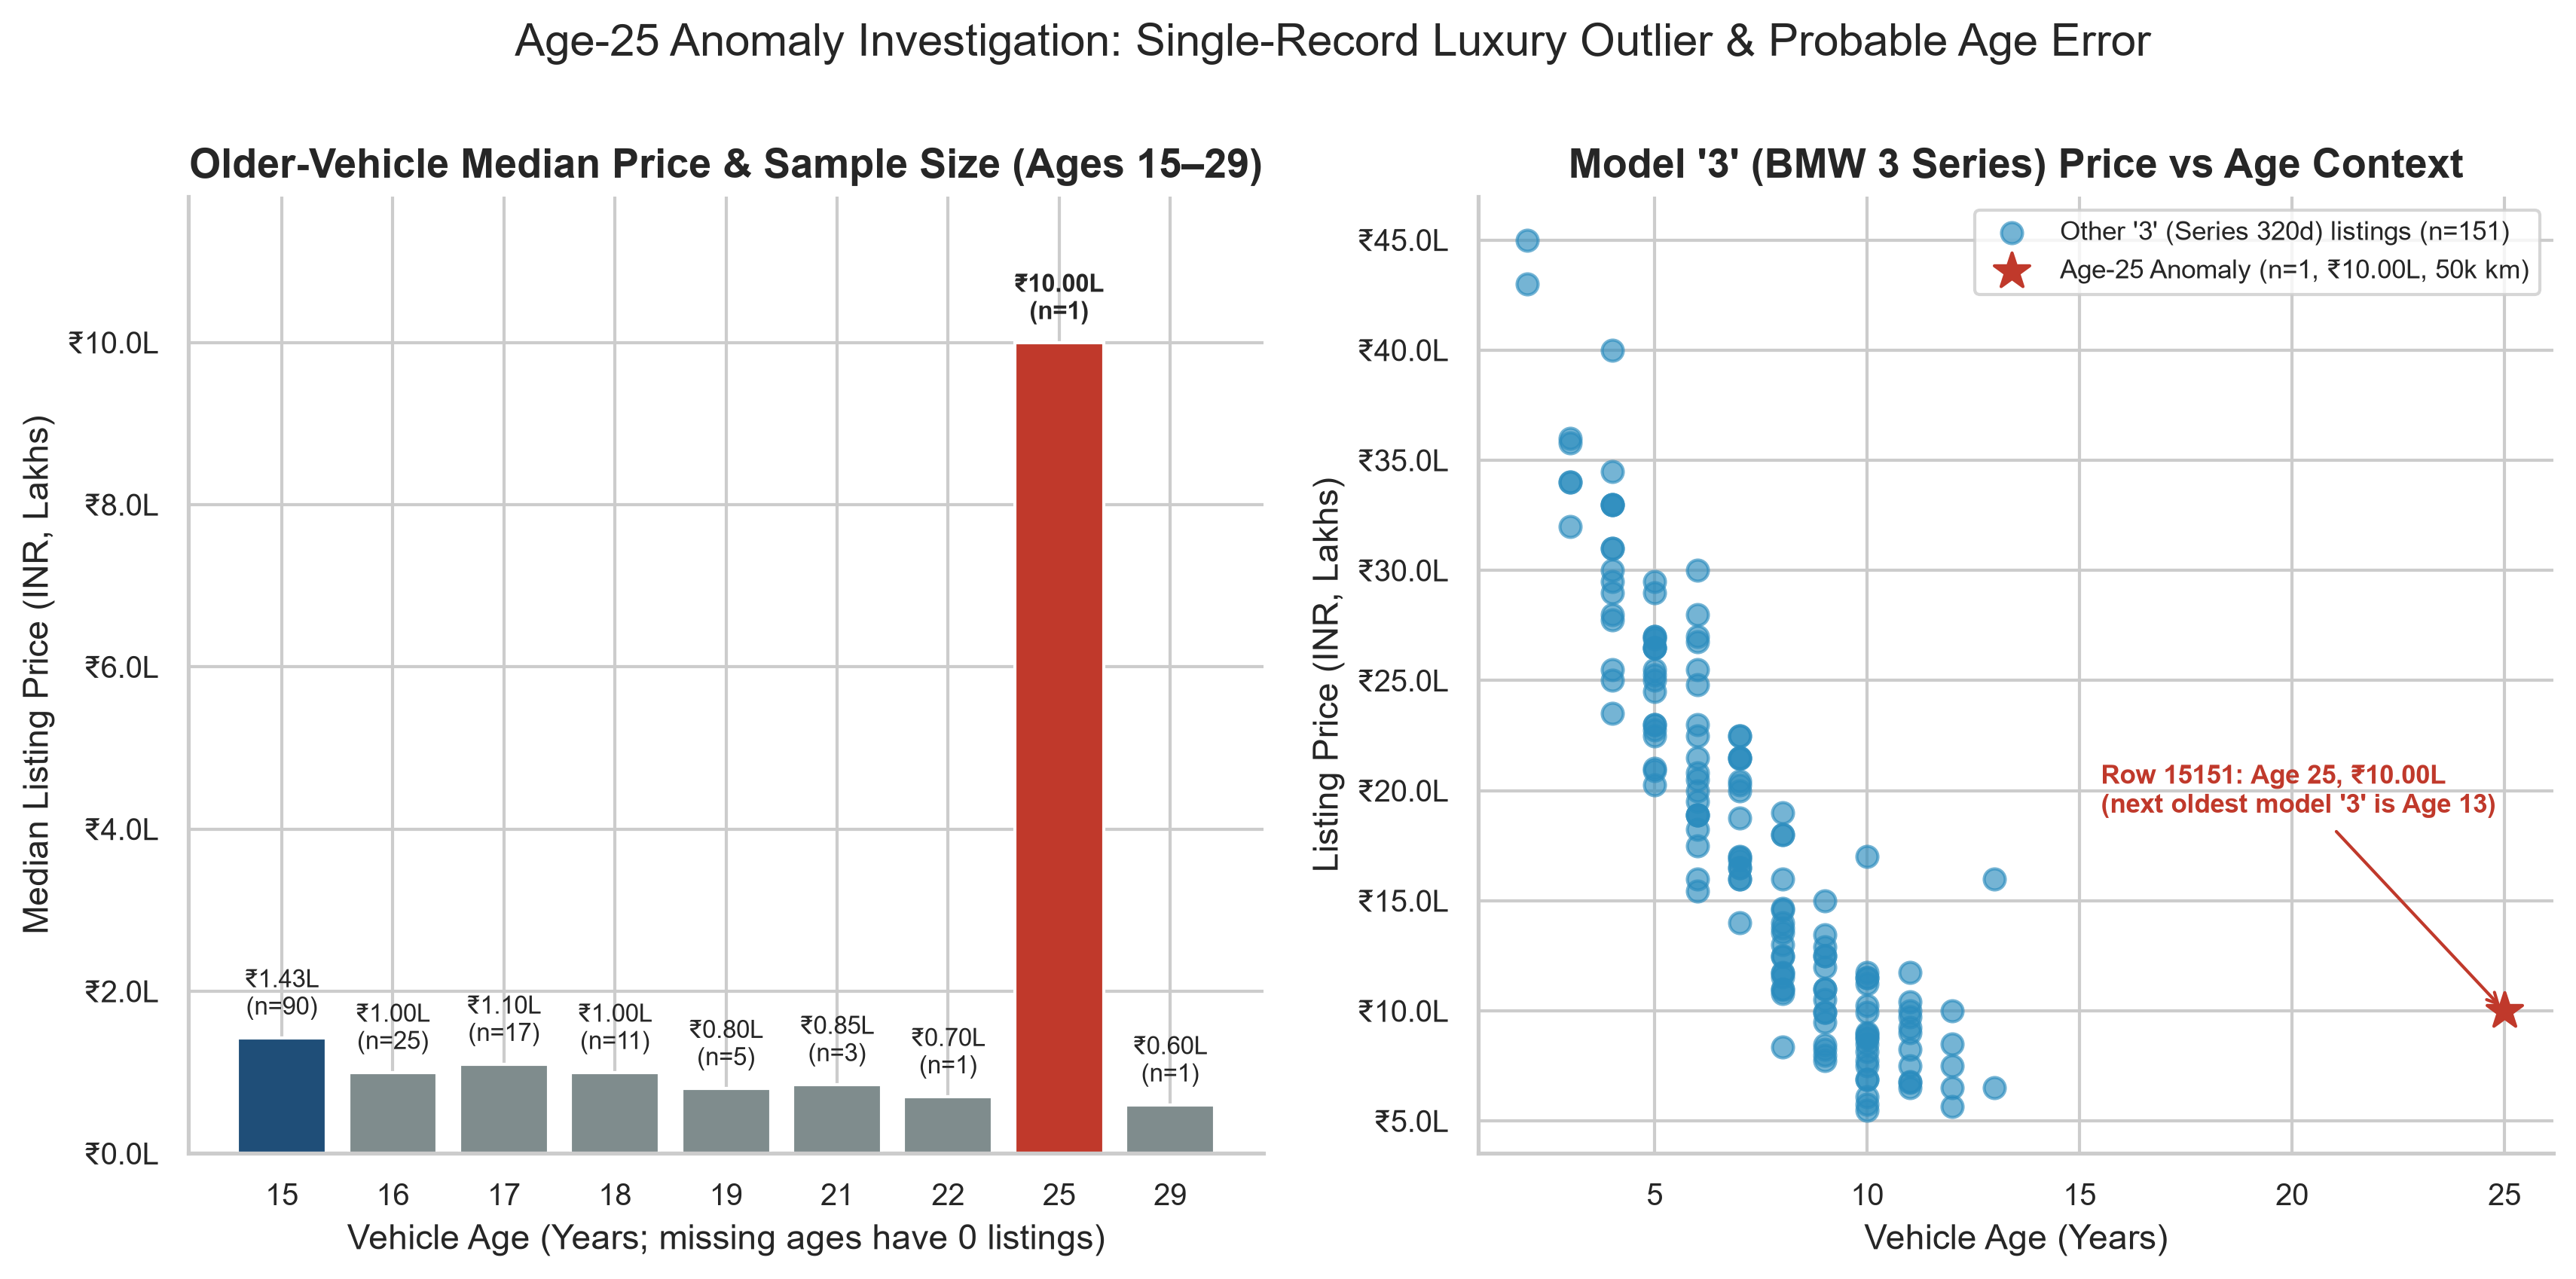

In [4]:
res1 = run_depreciation_analysis(df)
reg_df = pd.concat([
    pd.DataFrame(res1["regression_reliable"]),
    pd.DataFrame(res1["regression_all_sensitivity"]),
], ignore_index=True)
display(reg_df[["subset", "model", "n_obs", "r2_price_scale", "log_r2", "rmse_inr", "mae_inr", "aic"]])
print("\nMultivariate controlled age effect (Ages 1-15, n=15,161):")
print(res1["multivariate_age_control"])

for fname in ["depreciation_curve.png", "vehicle_age_sample_size.png", "annual_price_change.png", "age_25_anomaly.png"]:
    print(f"--- {fname} ---")
    display(Image(filename=str(OUTPUT_FIG_DIR / fname), width=780))

### Modeling Comparison & Conclusion
- **Why Log-Price / Piecewise Log-Linear Wins:** Raw linear and polynomial OLS on INR prices achieve only `R² ≈ 0.056–0.057` with `₹8.69L` RMSE because listing prices span two orders of magnitude (`₹0.40L–₹395.0L`) and exhibit multiplicative depreciation. Modeling `log(selling_price)` with piecewise knots at **Age 5 and Age 10** raises `log R²` to **0.2268** (vs. `0.2194` log-linear) and improves log-AIC by **140.3 points** (`27,507.6 -> 27,367.3`).
- **Sensitivity Check:** Including the 68 low-sample records (`0, 16–29`) slightly flattens the post-10 slope (`-0.0898` to `-0.0751`) because the single Age-25 `₹10.00L` outlier pulls up the tail, confirming the value of the `n >= 30` filter.
- **Controlled Effect:** Controlling for `km_driven`, `engine`, `max_power`, `transmission_type`, `seller_type`, and `model_grouped` yields **`R² = 0.9229`** and an estimated **`-10.60%` listing-price change per year of age** (95% CI: `[-11.39%, -11.02%]` log-points).